# Comparación de tiempo fijo, Q-Learning y DQN con cinco semillas

Este notebook evalúa los tres controladores sobre las mismas cinco realizaciones de demanda. No reentrena los modelos. Requiere haber ejecutado antes `Simulaciones_tiempos_fijos/baseline.ipynb`, `Q-Learning/qlearning.ipynb` y `DQN/dqn.ipynb`.

Genera `Comparativa/resultados/` con rutas, `tripinfo`, métricas por semilla, resumen, pruebas estadísticas y figuras.

In [1]:
import os
import pickle
import sys
import xml.etree.ElementTree as ET
from pathlib import Path
from xml.dom import minidom

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

_CWD = Path.cwd().resolve()
ROOT = _CWD if (_CWD / "Simple_Intersection.net.xml").exists() else _CWD.parent
VENV = ROOT / ".venv"
SUMO_HOME = VENV / "lib" / f"python{sys.version_info.major}.{sys.version_info.minor}" / "site-packages" / "sumo"
if not SUMO_HOME.exists():
    SUMO_HOME = VENV / "lib" / "python3.14" / "site-packages" / "sumo"
if not (SUMO_HOME / "tools").exists():
    raise SystemExit("No se encontró SUMO_HOME. Abre el notebook desde la raíz del repositorio y usa el kernel .venv.")
os.environ["SUMO_HOME"] = str(SUMO_HOME)
sys.path.append(str(SUMO_HOME / "tools"))

import gymnasium as gym
import sumolib
import traci
from scipy import stats
from stable_baselines3 import DQN
from sumo_rl import SumoEnvironment

NET = ROOT / "Simple_Intersection.net.xml"
ROUTE_DIR = ROOT / "Distribuciones"
QTABLE_PATH = ROOT / "Q-Learning" / "resultados" / "qlearning.pkl"
DQN_PATH = ROOT / "DQN" / "resultados" / "best_model.zip"
EDGES_PATH = ROOT / "Simulaciones_tiempos_fijos" / "resultados" / "bin_edges_calibrados.npz"
OUT_DIR = ROOT / "Comparativa" / "resultados"
SEEDS = [42, 43, 44, 45, 46]

DURACION = 3600
K_WEIBULL = 2.5
C_WEIBULL = 0.55 * DURACION
CONTEOS_MANUALES = np.array([135, 60, 33, 116, 120, 132, 38], dtype=float)
DURACIONES_MUESTRAS = np.array([410, 192, 92, 330, 344, 410, 119], dtype=float)
FLUJO_MEDIO_VEH_H = float((CONTEOS_MANUALES / DURACIONES_MUESTRAS * 3600).mean())
VEHICULOS_POR_ACCESO = int(round(FLUJO_MEDIO_VEH_H))

ACCESOS = [
    {"nombre": "Oeste", "rutas": [("ruta_OE", "-E4", "E3", 0.70), ("ruta_OS", "-E4", "E6", 0.30)]},
    {"nombre": "Norte", "rutas": [("ruta_NS", "-E5", "E6", 0.70), ("ruta_NE", "-E5", "E3", 0.30)]},
]
CONTEOS_TIPO = {"car": 7032, "moto": 885, "bus": 2189}
TOTAL_TIPOS = sum(CONTEOS_TIPO.values())
TIPOS = [
    ("car", "passenger", CONTEOS_TIPO["car"] / TOTAL_TIPOS),
    ("moto", "motorcycle", CONTEOS_TIPO["moto"] / TOTAL_TIPOS),
    ("bus", "bus", CONTEOS_TIPO["bus"] / TOTAL_TIPOS),
]


## 1. Generación de demanda

Cada semilla produce una ruta Weibull independiente con 2410 vehículos. La red es la misma de 300 m.

In [2]:
def generar_tiempos_weibull(seed: int, seed_offset: int, total: int) -> list[float]:
    rng = np.random.default_rng(seed + seed_offset)
    tiempos = np.empty(0)
    while tiempos.size < total:
        u = rng.uniform(0, 1, size=total - tiempos.size)
        t = C_WEIBULL * (-np.log(u)) ** (1 / K_WEIBULL)
        tiempos = np.concatenate([tiempos, t[t <= DURACION]])
    return sorted(tiempos.tolist())


def generar_ruta(seed: int, destino: Path) -> Path:
    tiempos_oeste = generar_tiempos_weibull(seed, 0, VEHICULOS_POR_ACCESO)
    tiempos_norte = generar_tiempos_weibull(seed, 10, VEHICULOS_POR_ACCESO)
    por_acceso = [(tiempos_oeste, seed + 1), (tiempos_norte, seed + 11)]

    root = ET.Element("routes")
    root.set("xmlns:xsi", "http://www.w3.org/2001/XMLSchema-instance")
    root.set("xsi:noNamespaceSchemaLocation", "http://sumo.dlr.de/xsd/routes_file.xsd")

    for tipo, clase, _ in TIPOS:
        atributos = {
            "car": dict(accel="3.0", decel="4.5", sigma="0.5", length="5.0", minGap="2.5", maxSpeed="13.9"),
            "moto": dict(accel="3.5", decel="5.0", sigma="0.6", length="2.2", minGap="2.0", maxSpeed="16.7"),
            "bus": dict(accel="2.0", decel="4.5", sigma="0.3", length="12.0", minGap="2.5", maxSpeed="11.1"),
        }[tipo]
        ET.SubElement(root, "vType", id=tipo, vClass=clase, carFollowModel="Krauss", **atributos)

    for acceso in ACCESOS:
        for rid, e_from, e_to, _ in acceso["rutas"]:
            ET.SubElement(root, "route", id=rid, edges=f"{e_from} {e_to}")

    todos = []
    for acceso, (tiempos, rng_seed) in zip(ACCESOS, por_acceso):
        rng = np.random.default_rng(rng_seed)
        rutas = acceso["rutas"]
        p_ruta = np.array([r[3] for r in rutas], dtype=float)
        p_ruta /= p_ruta.sum()
        p_tipo = np.array([t[2] for t in TIPOS], dtype=float)
        p_tipo /= p_tipo.sum()
        idx_ruta = rng.choice(len(rutas), size=len(tiempos), p=p_ruta)
        idx_tipo = rng.choice(len(TIPOS), size=len(tiempos), p=p_tipo)
        for t, ir, it in zip(tiempos, idx_ruta, idx_tipo):
            todos.append({"depart": t, "type": TIPOS[it][0], "route": rutas[ir][0]})

    todos.sort(key=lambda x: x["depart"])
    for i, v in enumerate(todos):
        ET.SubElement(
            root,
            "vehicle",
            id=f"veh_{i}",
            type=v["type"],
            route=v["route"],
            depart=f"{v['depart']:.2f}",
            departLane="best",
            departSpeed="0",
        )

    destino.parent.mkdir(parents=True, exist_ok=True)
    xml_str = ET.tostring(root, encoding="utf-8")
    pretty = minidom.parseString(xml_str).toprettyxml(indent="    ")
    destino.write_text(pretty, encoding="utf-8")
    return destino




## 2. Wrappers de estado y acción

`VariableGreenWrapper` aplica las 12 duraciones de verde. `TrafficStateWrapper` discretiza las cuatro variables para Q-Learning. `FourVarObservationWrapper` entrega las mismas cuatro variables normalizadas a DQN.

In [3]:
class VariableGreenWrapper(gym.Wrapper):
    DURACIONES = list(range(5, 65, 5))

    def __init__(self, env, delta_time=5):
        super().__init__(env)
        self.delta_time = delta_time
        self.action_space = gym.spaces.Discrete(len(self.DURACIONES))
        self._fase_actual = 0
        self.queue_samples = []

    def step(self, action_idx):
        duracion = self.DURACIONES[action_idx]
        n_pasos = duracion // self.delta_time
        reward_acumulado = 0.0
        terminated = truncated = False
        info = {}
        for _ in range(n_pasos):
            obs, reward, terminated, truncated, info = self.env.step(self._fase_actual)
            reward_acumulado += reward
            self.queue_samples.append(float(info.get("system_total_stopped", 0)))
            if terminated or truncated:
                break
            if self.env.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
                break
        self._fase_actual = 1 - self._fase_actual
        return obs, reward_acumulado, terminated, truncated, info

    def reset(self, **kwargs):
        self._fase_actual = 0
        self.queue_samples = []
        return self.env.reset(**kwargs)


class TrafficStateWrapper(gym.Wrapper):
    def __init__(self, env, edges):
        super().__init__(env)
        self.observation_space = gym.spaces.MultiDiscrete([6, 6, 4, 3])
        self.edges = edges
        self._seen_departures = {}

    def _compute_state(self):
        sumo = self.env.unwrapped.sumo
        sim_time = float(sumo.simulation.getTime())
        ids = sumo.vehicle.getIDList()
        for v in ids:
            self._seen_departures.setdefault(v, sim_time)
        self._seen_departures = {
            v: t for v, t in self._seen_departures.items()
            if sim_time - t <= 30
        }
        n_vehiculos = len(ids)
        waiting = float(np.mean([sumo.vehicle.getWaitingTime(v) for v in ids])) if ids else 0.0
        ts = self.env.unwrapped.traffic_signals[self.env.unwrapped.ts_ids[0]]
        queue = float(ts.get_total_queued())
        arrival = float(sum(
            1 for t in self._seen_departures.values()
            if sim_time - 30 <= t <= sim_time
        ))
        return (
            int(np.digitize(n_vehiculos, self.edges["nvehiculos"])),
            int(np.digitize(waiting, self.edges["waiting"])),
            int(np.digitize(queue, self.edges["queue"])),
            int(np.digitize(arrival, self.edges["arrival"])),
        )

    def reset(self, **kwargs):
        self._seen_departures = {}
        obs, info = self.env.reset(**kwargs)
        return self._compute_state(), info

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        return self._compute_state(), reward, terminated, truncated, info


class FourVarObservationWrapper(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(low=0.0, high=1.0, shape=(4,), dtype=np.float32)
        self._seen_departures = {}

    def reset(self, **kwargs):
        self._seen_departures = {}
        return super().reset(**kwargs)

    def observation(self, obs):
        sumo = self.env.unwrapped.sumo
        sim_time = float(sumo.simulation.getTime())
        ids = sumo.vehicle.getIDList()
        for v in ids:
            self._seen_departures.setdefault(v, sim_time)
        self._seen_departures = {
            v: t for v, t in self._seen_departures.items()
            if sim_time - t <= 30
        }
        n_vehiculos = len(ids)
        waiting = float(np.mean([sumo.vehicle.getWaitingTime(v) for v in ids])) if ids else 0.0
        ts = self.env.unwrapped.traffic_signals[self.env.unwrapped.ts_ids[0]]
        queue = float(ts.get_total_queued())
        arrival = float(sum(
            1 for t in self._seen_departures.values()
            if sim_time - 30 <= t <= sim_time
        ))
        state = np.array(
            [n_vehiculos / 150.0, waiting / 30.0, queue / 80.0, arrival / 40.0],
            dtype=np.float32,
        )
        return np.clip(state, 0.0, 1.0)




## 3. Métricas

El tiempo de espera, el tiempo perdido y la velocidad se obtienen por viaje desde `tripinfo.xml`. La cola se mide en cada paso de 5 s como número de vehículos detenidos.

In [4]:
def parse_tripinfo(path: Path) -> dict:
    root = ET.parse(path).getroot()
    rows = []
    for trip in root.findall("tripinfo"):
        duration = float(trip.get("duration", 0))
        route_length = float(trip.get("routeLength", 0))
        rows.append(
            {
                "espera": float(trip.get("waitingTime", 0)),
                "tiempo_perdido": float(trip.get("timeLoss", 0)),
                "velocidad": (route_length / duration) * 3.6 if duration > 0 else 0.0,
                "llegada": float(trip.get("arrival", 0)),
            }
        )
    if not rows:
        raise RuntimeError(f"No hay viajes en {path}")
    df = pd.DataFrame(rows)
    return {
        "vehiculos": int(len(df)),
        "espera_promedio": float(df["espera"].mean()),
        "espera_maxima": float(df["espera"].max()),
        "tiempo_perdido": float(df["tiempo_perdido"].mean()),
        "velocidad_promedio": float(df["velocidad"].mean()),
        "ultima_llegada": float(df["llegada"].max()),
    }


def resumen_cola(valores: list[float]) -> dict:
    if not valores:
        return {"cola_promedio": float("nan"), "cola_maxima": float("nan")}
    return {
        "cola_promedio": float(np.mean(valores)),
        "cola_maxima": float(np.max(valores)),
    }




## 4. Ejecución de los tres controladores

Tiempo fijo usa TraCI directamente. Q-Learning y DQN usan SUMO-RL con `yellow_time=3`, `min_green=5` y `delta_time=5`.

In [5]:
def ejecutar_tiempo_fijo(route: Path, seed: int, tripinfo: Path) -> dict:
    tripinfo.unlink(missing_ok=True)
    sumo_bin = sumolib.checkBinary("sumo")
    cmd = [
        sumo_bin,
        "-n", str(NET),
        "-r", str(route),
        "--seed", str(seed),
        "--no-step-log", "true",
        "--tripinfo-output", str(tripinfo),
        "-W",
    ]
    colas = []
    tiempo_final = 0.0
    traci.start(cmd)
    try:
        while traci.simulation.getMinExpectedNumber() > 0:
            traci.simulationStep()
            tiempo_final = float(traci.simulation.getTime())
            if int(round(tiempo_final)) % 5 != 0:
                continue
            ids = traci.vehicle.getIDList()
            colas.append(sum(1 for v in ids if traci.vehicle.getSpeed(v) < 0.1))
    finally:
        traci.close()
    datos = parse_tripinfo(tripinfo)
    datos.update(resumen_cola(colas))
    datos["tiempo_simulacion"] = tiempo_final
    return datos


def _entorno(route: Path, seed: int, tripinfo: Path) -> SumoEnvironment:
    return SumoEnvironment(
        net_file=str(NET),
        route_file=str(route),
        out_csv_name=None,
        single_agent=True,
        use_gui=False,
        num_seconds=100000,
        delta_time=5,
        yellow_time=3,
        min_green=5,
        time_to_teleport=-1,
        sumo_seed=seed,
        additional_sumo_cmd=f"-W --no-step-log --tripinfo-output {tripinfo}",
    )


def ejecutar_qlearning(route: Path, seed: int, tripinfo: Path, tabla_q: dict, edges: dict) -> dict:
    tripinfo.unlink(missing_ok=True)
    env = _entorno(route, seed, tripinfo)
    env = VariableGreenWrapper(env, delta_time=5)
    env = TrafficStateWrapper(env, edges)
    obs, _ = env.reset(seed=seed)
    ultima_accion = 5
    tiempo_final = 0.0
    try:
        done = False
        while not done:
            estado = tuple(obs)
            accion = int(np.argmax(tabla_q[estado])) if estado in tabla_q else ultima_accion
            ultima_accion = accion
            obs, _, terminated, truncated, info = env.step(accion)
            tiempo_final = float(env.unwrapped.sim_step)
            if env.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
                break
            done = terminated or truncated
        colas = env.env.queue_samples
    finally:
        env.close()
    datos = parse_tripinfo(tripinfo)
    datos.update(resumen_cola(colas))
    datos["tiempo_simulacion"] = tiempo_final
    return datos


def ejecutar_dqn(route: Path, seed: int, tripinfo: Path, modelo: DQN) -> dict:
    tripinfo.unlink(missing_ok=True)
    env = _entorno(route, seed, tripinfo)
    env = VariableGreenWrapper(env, delta_time=5)
    env = FourVarObservationWrapper(env)
    obs, _ = env.reset(seed=seed)
    tiempo_final = 0.0
    try:
        done = False
        while not done:
            accion, _ = modelo.predict(obs, deterministic=True)
            obs, _, terminated, truncated, info = env.step(int(accion))
            tiempo_final = float(env.unwrapped.sim_step)
            if env.unwrapped.sumo.simulation.getMinExpectedNumber() == 0:
                break
            done = terminated or truncated
        colas = env.env.queue_samples
    finally:
        env.close()
    datos = parse_tripinfo(tripinfo)
    datos.update(resumen_cola(colas))
    datos["tiempo_simulacion"] = tiempo_final
    return datos




## 5. Resumen, pruebas y figuras

Se guardan las métricas por semilla, el resumen por controlador y las pruebas t pareada y Wilcoxon. Con n=5, Wilcoxon no alcanza p<0,05 bilateral; se reporta junto con la t pareada.

In [6]:
def guardar_tablas(df: pd.DataFrame, out: Path) -> None:
    df.to_csv(out / "metricas_por_semilla.csv", index=False)
    resumen = (
        df.groupby("controlador")
        .agg(
            espera_media=("espera_promedio", "mean"),
            espera_std=("espera_promedio", "std"),
            cola_media=("cola_promedio", "mean"),
            cola_std=("cola_promedio", "std"),
            velocidad_media=("velocidad_promedio", "mean"),
            tiempo_perdido_medio=("tiempo_perdido", "mean"),
        )
        .reset_index()
    )
    resumen.to_csv(out / "resumen.csv", index=False)

    pares = [("DQN", "Tiempo fijo"), ("Q-Learning", "Tiempo fijo"), ("DQN", "Q-Learning")]
    pruebas = []
    for metrica in ["espera_promedio", "cola_promedio"]:
        pivote = df.pivot(index="semilla", columns="controlador", values=metrica)
        for a, b in pares:
            x = pivote[a].to_numpy()
            y = pivote[b].to_numpy()
            diferencias = x - y
            n = len(diferencias)
            se = diferencias.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
            tcrit = stats.t.ppf(0.975, n - 1) if n > 1 else np.nan
            t_stat, p_t = stats.ttest_rel(x, y)
            try:
                w_stat, p_w = stats.wilcoxon(x, y)
            except ValueError:
                w_stat, p_w = np.nan, np.nan
            pruebas.append(
                {
                    "metrica": metrica,
                    "contraste": f"{a} vs {b}",
                    "n": n,
                    "diferencia_media": float(diferencias.mean()),
                    "ic95_inferior": float(diferencias.mean() - tcrit * se),
                    "ic95_superior": float(diferencias.mean() + tcrit * se),
                    "p_t_pareada": float(p_t),
                    "p_wilcoxon": float(p_w),
                }
            )
    pd.DataFrame(pruebas).to_csv(out / "pruebas.csv", index=False)


def guardar_figuras(df: pd.DataFrame, out: Path) -> None:
    fig_dir = out / "figuras"
    fig_dir.mkdir(parents=True, exist_ok=True)
    for metrica, etiqueta in [
        ("espera_promedio", "Tiempo promedio de espera (s)"),
        ("cola_promedio", "Cola promedio (vehículos detenidos)"),
    ]:
        resumen = df.groupby("controlador")[metrica].agg(["mean", "std"])
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.bar(resumen.index, resumen["mean"], yerr=resumen["std"], capsize=5, color=["#6b7280", "#2563eb", "#dc2626"])
        ax.set_ylabel(etiqueta)
        ax.set_xlabel("Controlador")
        ax.set_title(f"{etiqueta} por controlador (5 semillas)")
        ax.grid(axis="y", alpha=0.3)
        fig.tight_layout()
        fig.savefig(fig_dir / f"{metrica}.png", dpi=200)
        plt.close(fig)




## 6. Ejecutar la comparación

Edita `SEEDS` en la primera celda si quieres otras semillas. La ejecución completa tarda varios minutos.

In [7]:
out = OUT_DIR.resolve()
(out / "rutas").mkdir(parents=True, exist_ok=True)
(out / "tripinfo").mkdir(parents=True, exist_ok=True)
(out / "figuras").mkdir(parents=True, exist_ok=True)

for requerido in [NET, QTABLE_PATH, DQN_PATH, EDGES_PATH]:
    if not requerido.exists():
        raise SystemExit(f"Falta {requerido}. Ejecuta primero los notebooks de entrenamiento.")

with open(QTABLE_PATH, "rb") as f:
    tabla_q = pickle.load(f)
if not tabla_q or len(next(iter(tabla_q))) != 4:
    raise SystemExit("La tabla Q no tiene estados de cuatro dimensiones. Reentrena Q-Learning.")

edges_npz = np.load(EDGES_PATH)
edges = {k: edges_npz[k] for k in ["nvehiculos", "waiting", "queue", "arrival"]}

modelo = DQN.load(DQN_PATH, device="auto")
if tuple(modelo.observation_space.shape) != (4,):
    raise SystemExit("El modelo DQN no tiene observación de cuatro variables. Reentrena DQN antes de comparar.")

filas = []
for seed in SEEDS:
    print(f"\nSemilla {seed}: generando demanda")
    ruta = generar_ruta(seed, out / "rutas" / f"loja_seed_{seed}.rou.xml")
    print(f"  {ruta.name}: {VEHICULOS_POR_ACCESO * 2} vehículos")

    trip = out / "tripinfo" / f"fijo_{seed}.xml"
    print("  Tiempo fijo")
    fila = ejecutar_tiempo_fijo(ruta, seed, trip)
    fila.update({"semilla": seed, "controlador": "Tiempo fijo"})
    filas.append(fila)

    trip = out / "tripinfo" / f"qlearning_{seed}.xml"
    print("  Q-Learning")
    fila = ejecutar_qlearning(ruta, seed, trip, tabla_q, edges)
    fila.update({"semilla": seed, "controlador": "Q-Learning"})
    filas.append(fila)

    trip = out / "tripinfo" / f"dqn_{seed}.xml"
    print("  DQN")
    fila = ejecutar_dqn(ruta, seed, trip, modelo)
    fila.update({"semilla": seed, "controlador": "DQN"})
    filas.append(fila)

df = pd.DataFrame(filas)
columnas = ["semilla", "controlador", "vehiculos", "espera_promedio", "espera_maxima", "cola_promedio", "cola_maxima", "velocidad_promedio", "tiempo_perdido", "tiempo_simulacion", "ultima_llegada"]
df = df[columnas]
guardar_tablas(df, out)
guardar_figuras(df, out)

print(f"Resultados en {out}")
display(df.groupby("controlador")[["espera_promedio", "cola_promedio"]].mean())
display(pd.read_csv(out / "resumen.csv"))
display(pd.read_csv(out / "pruebas.csv"))



Semilla 42: generando demanda
  loja_seed_42.rou.xml: 2410 vehículos
  Tiempo fijo
 Retrying in 1 seconds
  Q-Learning
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
  DQN
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds

Semilla 43: generando demanda
  loja_seed_43.rou.xml: 2410 vehículos
  Tiempo fijo
 Retrying in 1 seconds
  Q-Learning
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds
  DQN
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 2ms, vehicles TOT 0 ACT 0 BUF 0)                      
 Retrying in 1 seconds

Semilla 44: generando demanda
  loja_seed_44.rou.xml: 2410 vehículos
  Tiempo fijo
 Retrying in 1 seconds
  Q-Learning
 Retrying in 1 seconds
Step #0.00 (0ms ?*RT. ?UPS, TraCI: 1ms, vehicles TOT 0 ACT 0 

,espera_promedio,cola_promedio
controlador,,
DQN,29.041743,15.255524
Q-Learning,45.265311,27.687138
Tiempo fijo,56.338921,37.689710


,controlador,espera_media,espera_std,cola_media,cola_std,velocidad_media,tiempo_perdido_medio
0,DQN,29.041743,0.310283,15.255524,0.123946,12.849572,150.592979
1,Q-Learning,45.265311,0.753539,27.687138,0.556265,15.726620,109.046689
2,Tiempo fijo,56.338921,0.528960,37.689710,0.356532,18.129839,85.848876


,metrica,contraste,n,diferencia_media,ic95_inferior,ic95_superior,p_t_pareada,p_wilcoxon
0,espera_promedio,DQN vs Tiempo fijo,5,-27.297178,-28.277487,-26.316870,1.677610e-07,0.0625
1,espera_promedio,Q-Learning vs Tiempo fijo,5,-11.073610,-12.000324,-10.146896,4.922611e-06,0.0625
2,espera_promedio,DQN vs Q-Learning,5,-16.223568,-17.483666,-14.963471,3.655640e-06,0.0625
3,cola_promedio,DQN vs Tiempo fijo,5,-22.434185,-22.957151,-21.911220,2.980176e-08,0.0625
4,cola_promedio,Q-Learning vs Tiempo fijo,5,-10.002571,-10.639812,-9.365331,1.657445e-06,0.0625
5,cola_promedio,DQN vs Q-Learning,5,-12.431614,-13.158909,-11.704319,1.179350e-06,0.0625


## 7. Figuras

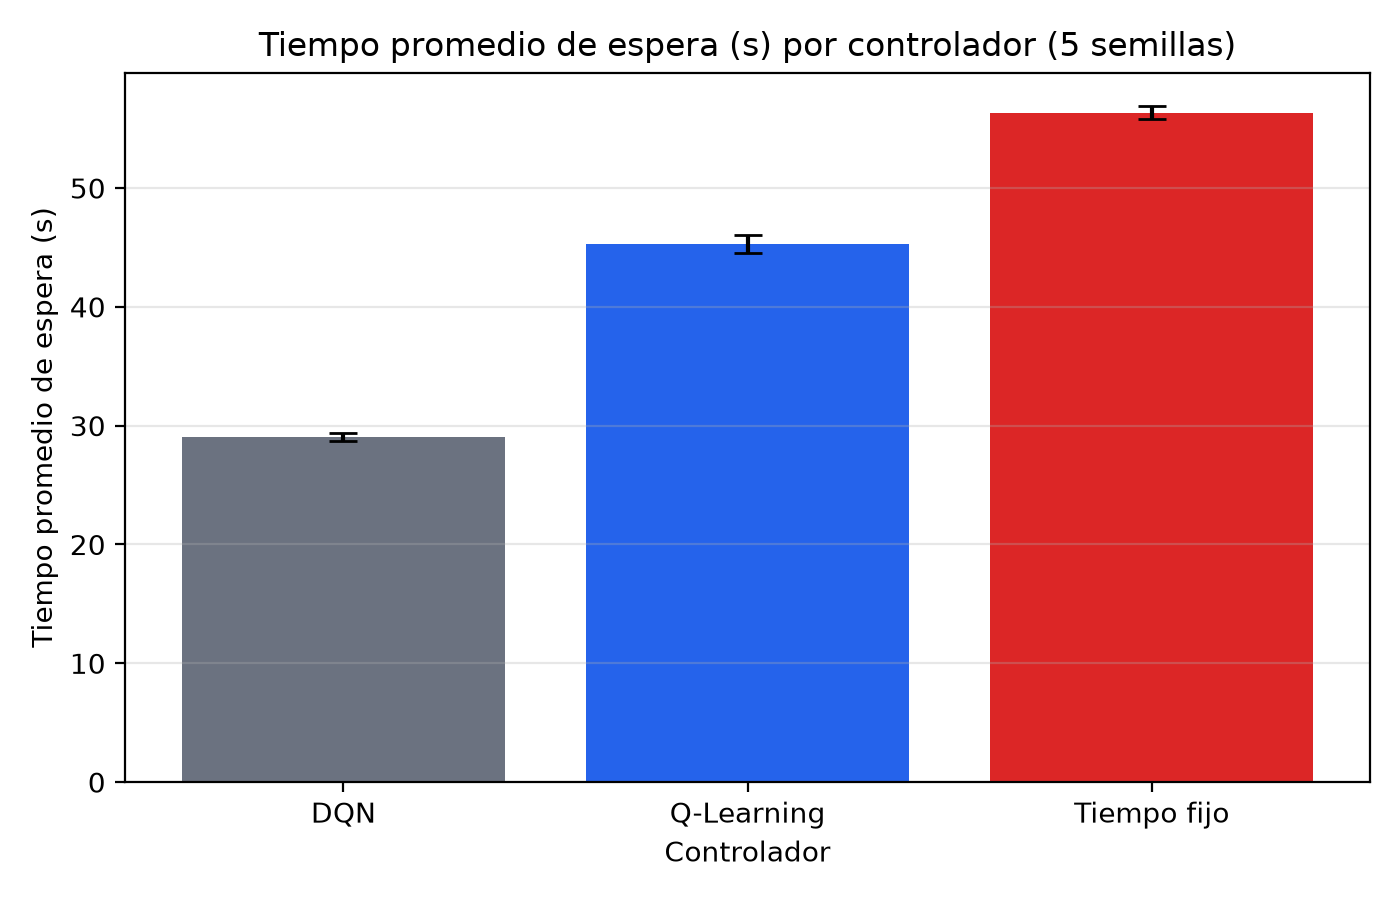

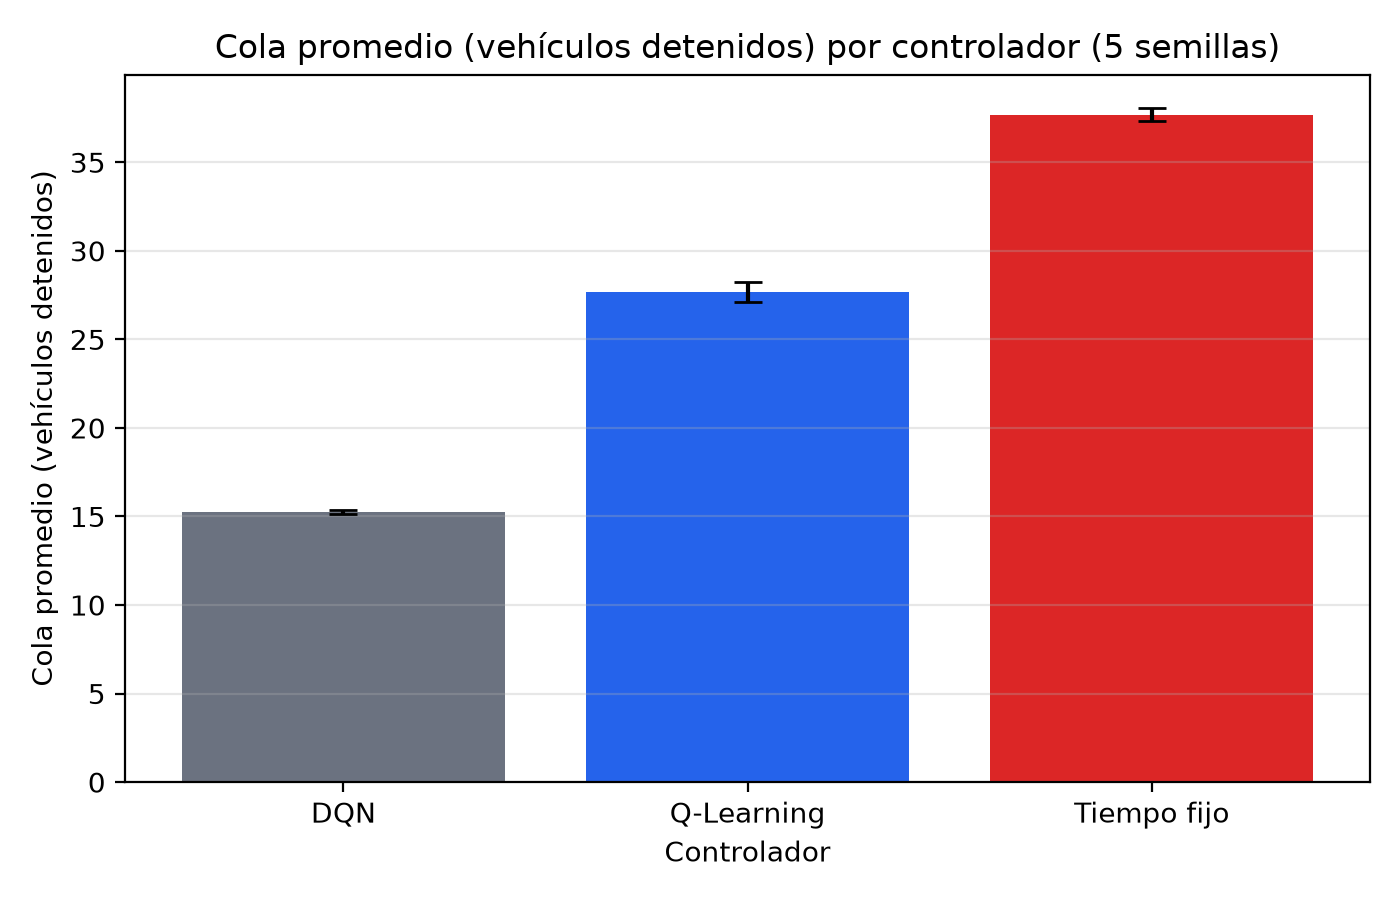

In [8]:
for nombre in ["espera_promedio", "cola_promedio"]:
    display(Image(filename=str(OUT_DIR / "figuras" / f"{nombre}.png")))
